In [9]:
# Connecting Drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [10]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
import cv2
from glob import glob
from collections import Counter
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import tensorflow as tf
import os
import pandas as pd
from glob import glob
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout, Flatten
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras import layers
from tensorflow.keras.models import Model, Sequential
from tensorflow.keras.applications import VGG16, EfficientNetB0
from warnings import filterwarnings
filterwarnings('ignore')

In [14]:
# load dataset
data_dir = '/content/drive/MyDrive/archive (4)/Vitiligo DS'  # Replace with your actual path
img_size = (224, 224)
batch_size = 32
num_classes = 2

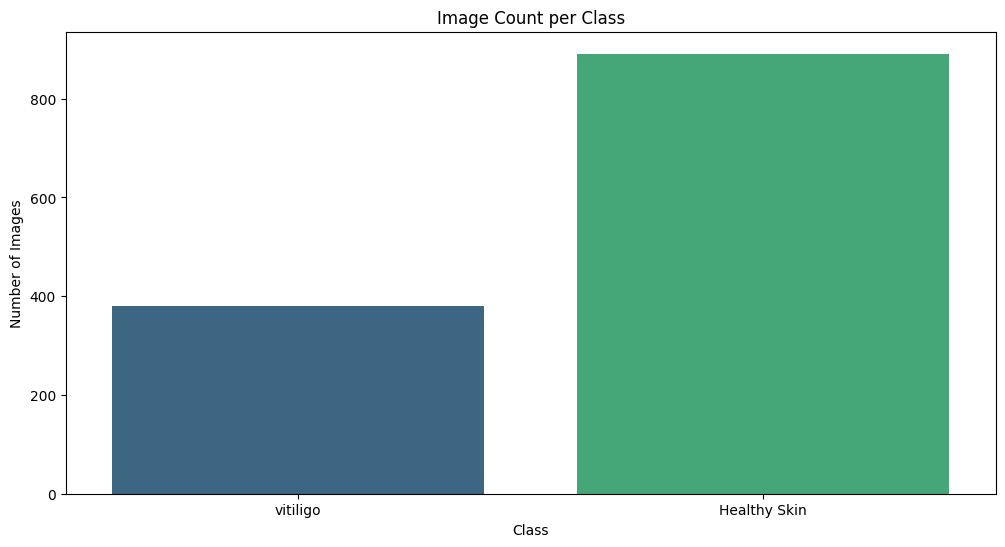

In [15]:
# Count images per class
class_counts = {}
for class_name in os.listdir(data_dir):
    class_dir = os.path.join(data_dir, class_name)
    if os.path.isdir(class_dir):
        image_files = glob(os.path.join(class_dir, '*'))
        class_counts[class_name] = len(image_files)

# Plot class distribution
plt.figure(figsize=(12, 6))
sns.barplot(x=list(class_counts.keys()), y=list(class_counts.values()), palette="viridis")
plt.title("Image Count per Class")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.show()

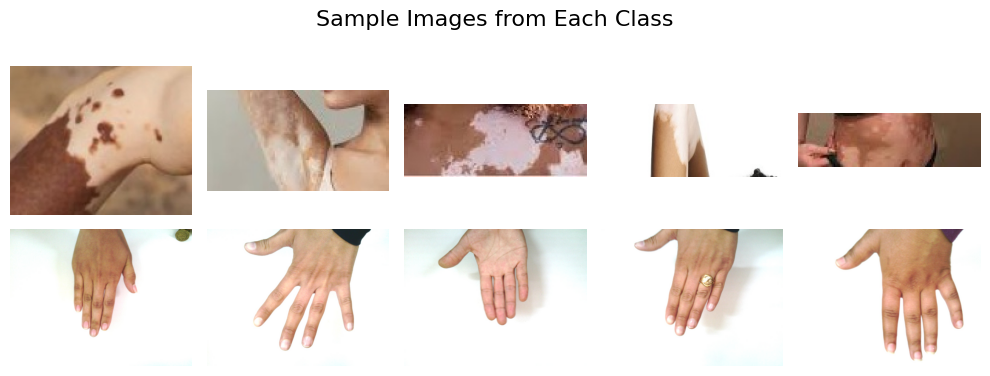

In [16]:
# Visualize sample images
def show_sample_images(dataset_path, classes, samples_per_class=5):
    plt.figure(figsize=(samples_per_class * 2, len(classes) * 2))
    for idx, class_name in enumerate(classes):
        image_files = glob(os.path.join(dataset_path, class_name, '*'))[:samples_per_class]
        for j, image_path in enumerate(image_files):
            img = cv2.imread(image_path)
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            plt.subplot(len(classes), samples_per_class, idx * samples_per_class + j + 1)
            plt.imshow(img)
            plt.axis('off')
            if j == 0:
                plt.ylabel(class_name, size=14)
    plt.suptitle("Sample Images from Each Class", size=16)
    plt.tight_layout()
    plt.show()

show_sample_images(data_dir, list(class_counts.keys()))

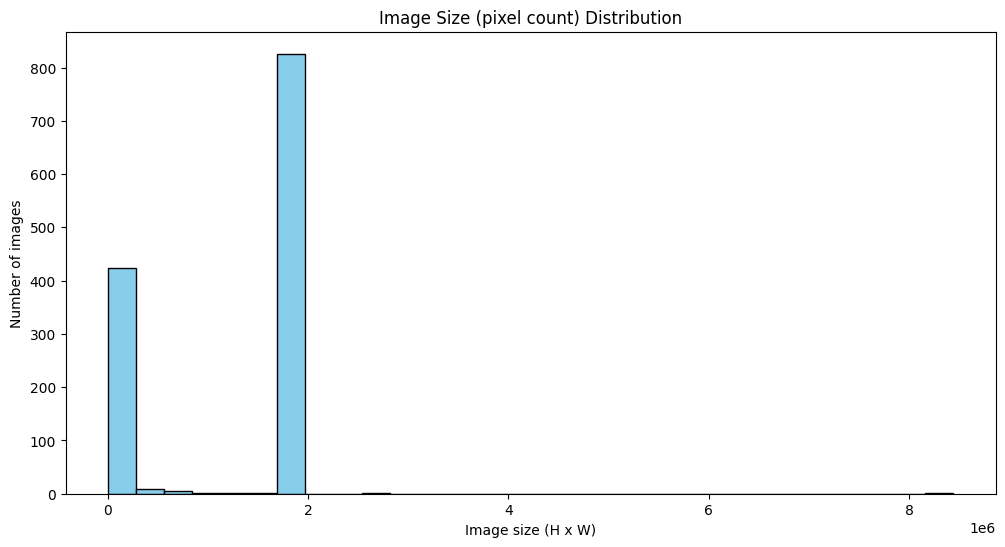

In [17]:
# Image dimension and size distribution
all_dims = []
image_sizes = []

for class_name in os.listdir(data_dir):
    class_dir = os.path.join(data_dir, class_name)
    for image_path in glob(os.path.join(class_dir, '*')):
        img = cv2.imread(image_path)
        if img is not None:
            h, w, c = img.shape
            all_dims.append((h, w))
            image_sizes.append(h * w)

# Image size histogram
plt.figure(figsize=(12, 6))
plt.hist(image_sizes, bins=30, color='skyblue', edgecolor='black')
plt.title("Image Size (pixel count) Distribution")
plt.xlabel("Image size (H x W)")
plt.ylabel("Number of images")
plt.show()

In [18]:
# Display the number of images in each class
print("Number of images in each class:")
for class_name, count in class_counts.items():
    print(f"{class_name}: {count}")

Number of images in each class:
vitiligo: 380
Healthy Skin: 891


In [19]:
total_images = sum(class_counts.values())
print(f"Total number of images in the dataset: {total_images}")

Total number of images in the dataset: 1271


In [20]:
image_paths = glob(os.path.join(data_dir, '*', '*'))

data = []
for path in image_paths:
    label = os.path.basename(os.path.dirname(path))
    data.append({'filepath': path, 'label': label})

df = pd.DataFrame(data)

In [21]:
df

,filepath,label
0,/content/drive/MyDrive/archive (4)/Vitiligo DS...,vitiligo
1,/content/drive/MyDrive/archive (4)/Vitiligo DS...,vitiligo
2,/content/drive/MyDrive/archive (4)/Vitiligo DS...,vitiligo
3,/content/drive/MyDrive/archive (4)/Vitiligo DS...,vitiligo
4,/content/drive/MyDrive/archive (4)/Vitiligo DS...,vitiligo
...,...,...
1266,/content/drive/MyDrive/archive (4)/Vitiligo DS...,Healthy Skin
1267,/content/drive/MyDrive/archive (4)/Vitiligo DS...,Healthy Skin
1268,/content/drive/MyDrive/archive (4)/Vitiligo DS...,Healthy Skin
1269,/content/drive/MyDrive/archive (4)/Vitiligo DS...,Healthy Skin


In [22]:
# Map string labels to binary
label_map = {'Healthy Skin': 0, 'vitiligo': 1}
df['label'] = df['label'].map(label_map)

In [23]:
#Balance Dataset by Oversampling

majority_df = df[df['label'] == 0]  # Healthy Skin
minority_df = df[df['label'] == 1]  # Vitiligo

# Oversample minority class to match majority
minority_oversampled_df = minority_df.sample(n=len(majority_df), replace=True, random_state=42)

# Combine and shuffle
balanced_df = pd.concat([majority_df, minority_oversampled_df]).sample(frac=1, random_state=42).reset_index(drop=True)


In [24]:
balanced_df

,filepath,label
0,/content/drive/MyDrive/archive (4)/Vitiligo DS...,0
1,/content/drive/MyDrive/archive (4)/Vitiligo DS...,1
2,/content/drive/MyDrive/archive (4)/Vitiligo DS...,0
3,/content/drive/MyDrive/archive (4)/Vitiligo DS...,0
4,/content/drive/MyDrive/archive (4)/Vitiligo DS...,0
...,...,...
1777,/content/drive/MyDrive/archive (4)/Vitiligo DS...,1
1778,/content/drive/MyDrive/archive (4)/Vitiligo DS...,1
1779,/content/drive/MyDrive/archive (4)/Vitiligo DS...,0
1780,/content/drive/MyDrive/archive (4)/Vitiligo DS...,1


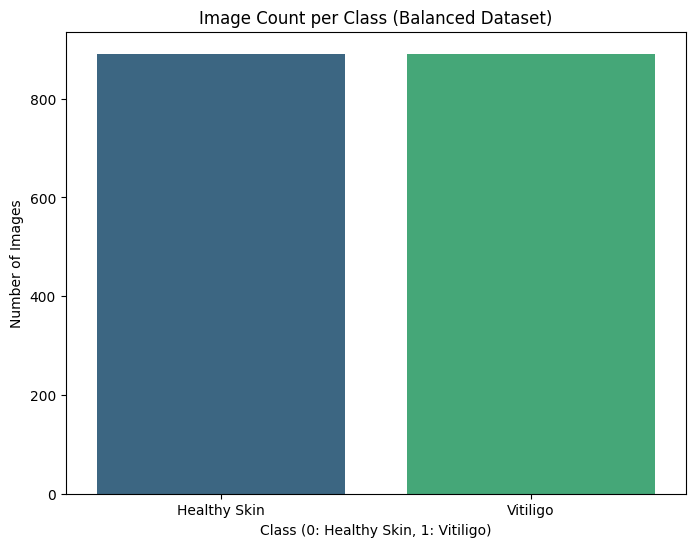

In [25]:
# Plot class distribution of the balanced dataset
plt.figure(figsize=(8, 6))
sns.countplot(x='label', data=balanced_df, palette="viridis")
plt.title("Image Count per Class (Balanced Dataset)")
plt.xlabel("Class (0: Healthy Skin, 1: Vitiligo)")
plt.ylabel("Number of Images")
plt.xticks(ticks=[0, 1], labels=['Healthy Skin', 'Vitiligo']) # Set custom labels for clarity
plt.show()

In [26]:
train_df, temp_df = train_test_split(balanced_df, test_size=0.3, stratify=balanced_df['label'], random_state=42)
val_df, test_df = train_test_split(temp_df, test_size=1/3, stratify=temp_df['label'], random_state=42)

In [27]:
print(len(train_df))
print(len(val_df))
print(len(test_df))

1247
356
179


In [28]:
train_df['label'] = train_df['label'].astype(str)
val_df['label'] = val_df['label'].astype(str)
test_df['label'] = test_df['label'].astype(str)

In [29]:
train_aug = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.2,
    shear_range=0.2,
    horizontal_flip=True,
    brightness_range=[0.8, 1.2],
    fill_mode='nearest'
)

val_test_aug = ImageDataGenerator(rescale=1./255)

# Build Generators from DataFrames
train_gen = train_aug.flow_from_dataframe(
    dataframe=train_df,
    x_col='filepath',
    y_col='label',
    target_size=img_size,
    batch_size=batch_size,
    class_mode='binary',
    shuffle=True,
    seed=42
)

val_gen = val_test_aug.flow_from_dataframe(
    dataframe=val_df,
    x_col='filepath',
    y_col='label',
    target_size=img_size,
    batch_size=batch_size,
    class_mode='binary',
    shuffle=False
)

test_gen = val_test_aug.flow_from_dataframe(
    dataframe=test_df,
    x_col='filepath',
    y_col='label',
    target_size=img_size,
    batch_size=batch_size,
    class_mode='binary',
    shuffle=False
)

Found 1247 validated image filenames belonging to 2 classes.
Found 356 validated image filenames belonging to 2 classes.
Found 179 validated image filenames belonging to 2 classes.


In [30]:
# Evaluation Function
def evaluate_model(model, val_gen, name="Model"):
    val_gen.reset()
    y_true = val_gen.classes
    y_pred = model.predict(val_gen, verbose=0)
    y_pred = np.round(y_pred).astype(int).reshape(-1)
    print(f"\n{name} Classification Report:")
    print(classification_report(y_true, y_pred, target_names=["Healthy", "Vitiligo"]))

In [31]:
def plot_history(history, model_name="Model"):
    plt.figure(figsize=(12, 5))

    # Plot training & validation accuracy values
    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'])
    plt.plot(history.history['val_accuracy'])
    plt.title(f'{model_name} Accuracy')
    plt.ylabel('Accuracy')
    plt.xlabel('Epoch')
    plt.legend(['Train', 'Validation'], loc='upper left')

    # Plot training & validation loss values
    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'])
    plt.plot(history.history['val_loss'])
    plt.title(f'{model_name} Loss')
    plt.ylabel('Loss')
    plt.xlabel('Epoch')
    plt.legend(['Train', 'Validation'], loc='upper left')

    plt.tight_layout()
    plt.show()

In [32]:
base_model = EfficientNetB0(include_top=False, weights='imagenet', input_shape=(img_size[0], img_size[1], 3))
base_model.trainable = True
for layer in base_model.layers[:100]:
        layer.trainable = False

x = GlobalAveragePooling2D()(base_model.output)
x = Dropout(0.4)(x)
x = Dense(128, activation='relu')(x)
x = Dropout(0.3)(x)
output = Dense(1, activation='sigmoid')(x)

efficient_fixed_model = Model(inputs=base_model.input, outputs=output)

efficient_fixed_model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
                                  loss='binary_crossentropy',
                                  metrics=['accuracy'])

print("\nTraining EfficientNetB0 (Fixed LR)...\n")
history_efficientnet = efficient_fixed_model.fit(
        train_gen,
        validation_data=val_gen,
        epochs=10
)

test_gen.reset()
y_true = test_gen.classes
y_pred = (efficient_fixed_model.predict(test_gen) > 0.5).astype(int)

print("\nEfficientNetB0 Classification Report:")
print(classification_report(y_true, y_pred, target_names=test_gen.class_indices.keys()))

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

Training EfficientNetB0 (Fixed LR)...

Epoch 1/10
39/39 ━━━━━━━━━━━━━━━━━━━━ 132s 2s/step - accuracy: 0.7233 - loss: 0.5316 - val_accuracy: 0.5000 - val_loss: 0.7030
Epoch 2/10
39/39 ━━━━━━━━━━━━━━━━━━━━ 26s 671ms/step - accuracy: 0.8335 - loss: 0.3243 - val_accuracy: 0.5000 - val_loss: 0.6972
Epoch 3/10
39/39 ━━━━━━━━━━━━━━━━━━━━ 26s 670ms/step - accuracy: 0.8868 - loss: 0.2496 - val_accuracy: 0.5000 - val_loss: 0.7076
Epoch 4/10
39/39 ━━━━━━━━━━━━━━━━━━━━ 41s 676ms/step - accuracy: 0.8993 - loss: 0.2281 - val_accuracy: 0.5000 - val_loss: 0.7170
Epoch 5/10
39/39 ━━━━━━━━━━━━━━━━━━━━ 27s 682ms/step - accuracy: 0.8806 - loss: 0.2430 - val_accuracy: 0.5056 - val_loss: 0.6880
Epoch 6/10
39/39 ━━━━━━━━━━━━━━━━━━━━ 26s 673ms/step - accuracy: 0.9252 - loss: 0.1887 - val_accuracy: 0.5000 - val_loss: 0.6304
Epoch 7/10
39/39 ━━━━━━━━━━━━━━━━━━━━ 27s 684ms/step - accuracy: 0.9220 - loss: 0.1857 - val_accuracy: 0.5815 - val_loss: 0.5722
Epoch 8/

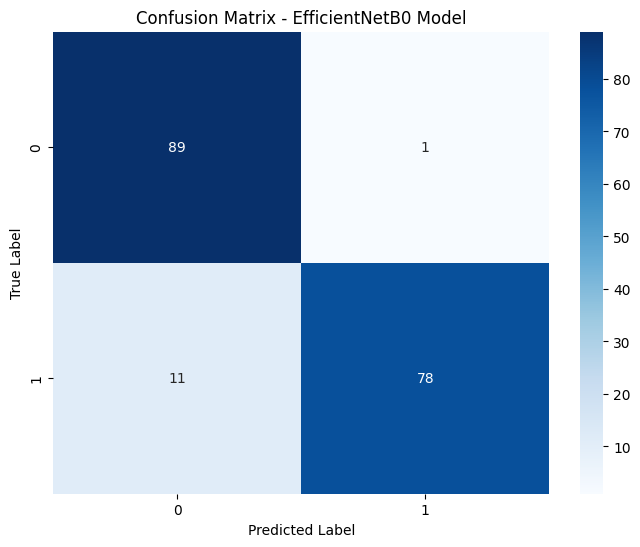

In [33]:
# Predict on test data to get the confusion matrix for the EfficientNet model
test_gen.reset()
y_true_efficientnet = test_gen.classes
y_pred_probs_efficientnet = efficient_fixed_model.predict(test_gen, verbose=0)
y_pred_efficientnet = (y_pred_probs_efficientnet > 0.5).astype(int).reshape(-1)

# Calculate confusion matrix for EfficientNet
cm_efficientnet = confusion_matrix(y_true_efficientnet, y_pred_efficientnet)

# Plot confusion matrix for EfficientNet
plt.figure(figsize=(8, 6))
sns.heatmap(cm_efficientnet, annot=True, fmt='d', cmap='Blues', xticklabels=test_gen.class_indices.keys(), yticklabels=test_gen.class_indices.keys())
plt.title('Confusion Matrix - EfficientNetB0 Model')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

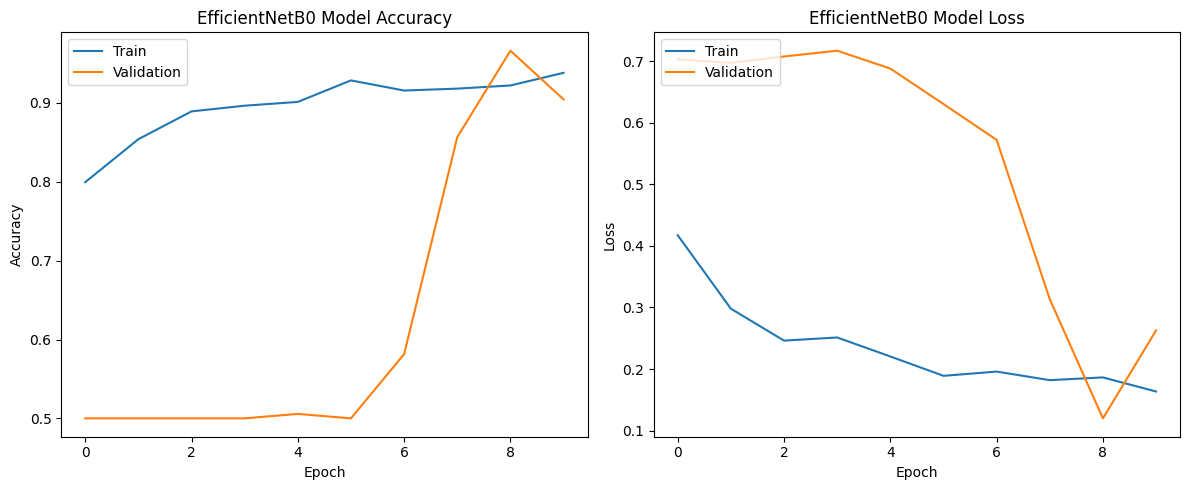

In [34]:
# Plot history for the EfficientNet model
plot_history(history_efficientnet, "EfficientNetB0 Model")

In [35]:
# Basic CNN
def build_basic_cnn():
    model = Sequential([
        layers.Input(shape=(224, 224, 3)),
        layers.Conv2D(32, (3, 3), activation='relu'),
        layers.MaxPooling2D(2, 2),
        layers.Conv2D(64, (3, 3), activation='relu'),
        layers.MaxPooling2D(2, 2),
        layers.Conv2D(128, (3, 3), activation='relu'),
        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.3),
        layers.Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return model

basic_model = build_basic_cnn()
print("Training Basic CNN...")
history_basic = basic_model.fit(train_gen, epochs=10, validation_data=val_gen)
evaluate_model(basic_model, test_gen, "Basic CNN")

Training Basic CNN...
Epoch 1/10
39/39 ━━━━━━━━━━━━━━━━━━━━ 40s 827ms/step - accuracy: 0.7584 - loss: 1.5749 - val_accuracy: 0.8680 - val_loss: 0.3267
Epoch 2/10
39/39 ━━━━━━━━━━━━━━━━━━━━ 26s 656ms/step - accuracy: 0.9398 - loss: 0.1657 - val_accuracy: 0.9213 - val_loss: 0.2018
Epoch 3/10
39/39 ━━━━━━━━━━━━━━━━━━━━ 26s 657ms/step - accuracy: 0.9361 - loss: 0.1687 - val_accuracy: 0.9579 - val_loss: 0.1553
Epoch 4/10
39/39 ━━━━━━━━━━━━━━━━━━━━ 25s 654ms/step - accuracy: 0.9341 - loss: 0.2019 - val_accuracy: 0.9635 - val_loss: 0.1404
Epoch 5/10
39/39 ━━━━━━━━━━━━━━━━━━━━ 25s 649ms/step - accuracy: 0.9615 - loss: 0.1269 - val_accuracy: 0.9438 - val_loss: 0.1443
Epoch 6/10
39/39 ━━━━━━━━━━━━━━━━━━━━ 25s 646ms/step - accuracy: 0.9565 - loss: 0.1499 - val_accuracy: 0.9607 - val_loss: 0.1215
Epoch 7/10
39/39 ━━━━━━━━━━━━━━━━━━━━ 41s 658ms/step - accuracy: 0.9614 - loss: 0.1330 - val_accuracy: 0.9691 - val_loss: 0.1180
Epoch 8/10
39/39 ━━━━━━━━━━━━━━━━━━━━ 26s 658ms/step - accuracy: 0.9632 - l

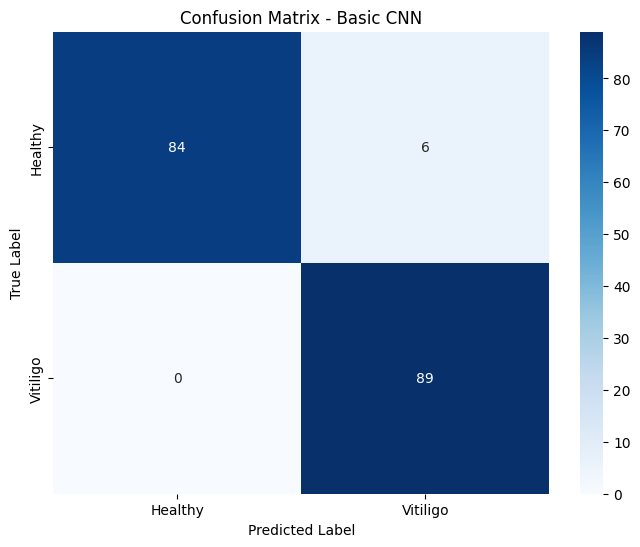

In [36]:
# Predict on test data to get the confusion matrix
test_gen.reset()
y_true = test_gen.classes
y_pred_probs = basic_model.predict(test_gen, verbose=0)
y_pred = np.round(y_pred_probs).astype(int).reshape(-1)

# Calculate confusion matrix
cm = confusion_matrix(y_true, y_pred)

# Plot confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=["Healthy", "Vitiligo"], yticklabels=["Healthy", "Vitiligo"])
plt.title('Confusion Matrix - Basic CNN')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

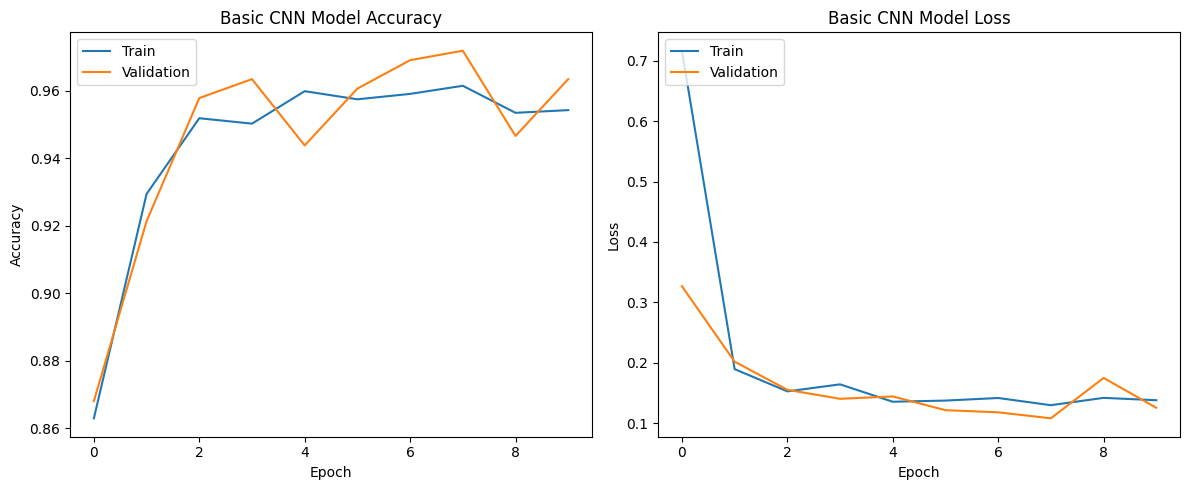

In [37]:
# Plot history for the Basic CNN model
plot_history(history_basic, "Basic CNN Model")

In [38]:
base_model = VGG16(include_top=False, weights='imagenet', input_shape=(img_size[0], img_size[1], 3))
base_model.trainable = False

x = Flatten()(base_model.output)
x = Dense(256, activation='relu')(x)
x = Dropout(0.4)(x)
predictions = Dense(1, activation='sigmoid')(x)

vgg16_fixed_model = Model(inputs=base_model.input, outputs=predictions)

vgg16_fixed_model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
                              loss='binary_crossentropy',
                              metrics=['accuracy'])

print("\nTraining VGG16 Model (Fixed LR)...\n")
history_vgg16 = vgg16_fixed_model.fit(
        train_gen,
        validation_data=val_gen,
        epochs=10
)

test_gen.reset()
y_true = test_gen.classes
y_pred = (vgg16_fixed_model.predict(test_gen) > 0.5).astype(int)

print("\nVGG16 Classification Report:")
print(classification_report(y_true, y_pred, target_names=test_gen.class_indices.keys()))

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step

Training VGG16 Model (Fixed LR)...

Epoch 1/10
39/39 ━━━━━━━━━━━━━━━━━━━━ 63s 1s/step - accuracy: 0.8659 - loss: 0.2812 - val_accuracy: 0.9860 - val_loss: 0.0586
Epoch 2/10
39/39 ━━━━━━━━━━━━━━━━━━━━ 27s 695ms/step - accuracy: 0.9860 - loss: 0.0542 - val_accuracy: 0.9860 - val_loss: 0.0521
Epoch 3/10
39/39 ━━━━━━━━━━━━━━━━━━━━ 27s 692ms/step - accuracy: 0.9859 - loss: 0.0418 - val_accuracy: 0.9860 - val_loss: 0.0433
Epoch 4/10
39/39 ━━━━━━━━━━━━━━━━━━━━ 27s 697ms/step - accuracy: 0.9843 - loss: 0.0468 - val_accuracy: 0.9860 - val_loss: 0.0500
Epoch 5/10
39/39 ━━━━━━━━━━━━━━━━━━━━ 27s 704ms/step - accuracy: 0.9885 - loss: 0.0397 - val_accuracy: 0.9860 - val_loss: 0.0366
Epoch 6/10
39/39 ━━━━━━━━━━━━━━━━━━━━ 27s 695ms/step - accuracy: 0.9920 - loss: 0.0298 - val_accuracy: 0.9860 - val_loss: 0.0349
Epoch 7/10
39/39 ━━━━━━━━━━━━━━━━━━━━ 27s 692ms/step - accuracy: 0.9931 - loss: 0.0224 - val_accuracy: 0.9860 - val_loss: 0.0457
Epoch 8/10
3

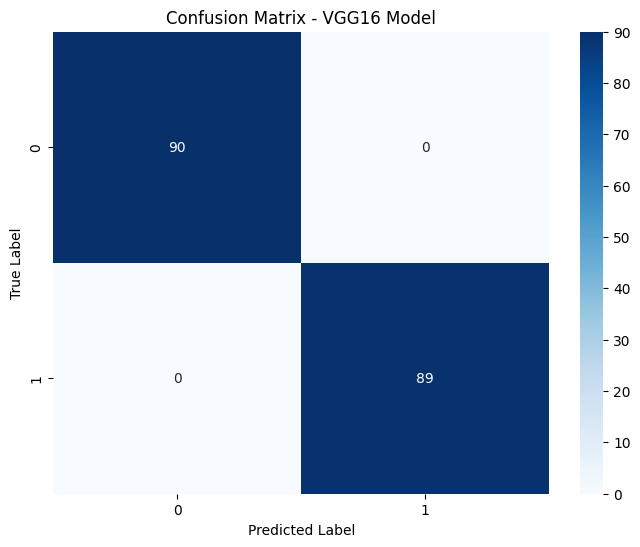

In [39]:
# Predict on test data to get the confusion matrix for the VGG16 model
test_gen.reset()
y_true_vgg16 = test_gen.classes
y_pred_probs_vgg16 = vgg16_fixed_model.predict(test_gen, verbose=0)
y_pred_vgg16 = (y_pred_probs_vgg16 > 0.5).astype(int).reshape(-1)

# Calculate confusion matrix for VGG16
cm_vgg16 = confusion_matrix(y_true_vgg16, y_pred_vgg16)

# Plot confusion matrix for VGG16
plt.figure(figsize=(8, 6))
sns.heatmap(cm_vgg16, annot=True, fmt='d', cmap='Blues', xticklabels=test_gen.class_indices.keys(), yticklabels=test_gen.class_indices.keys())
plt.title('Confusion Matrix - VGG16 Model')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

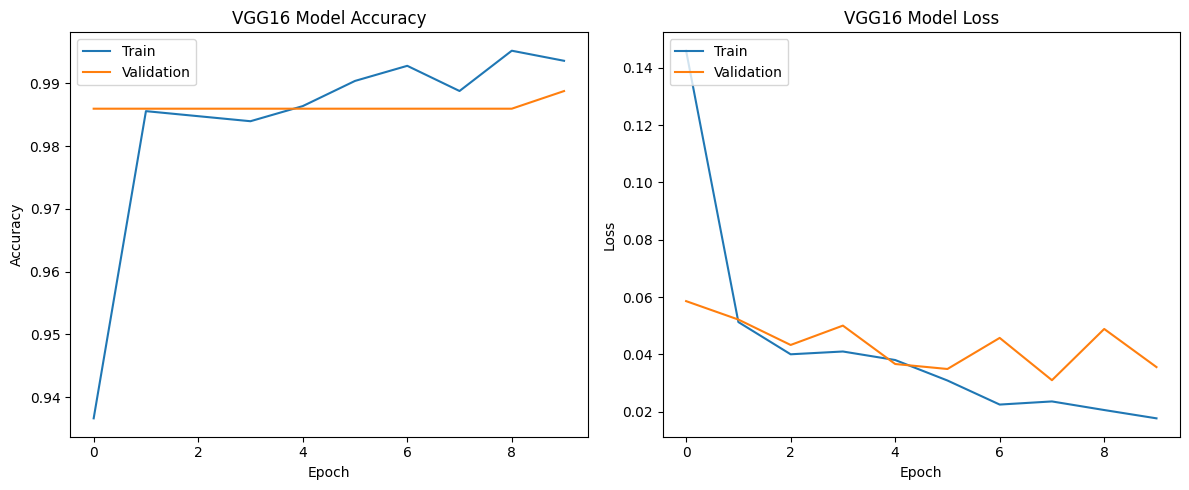

In [40]:
# Plot history for the VGG16 model
plot_history(history_vgg16, "VGG16 Model")

In [41]:
# Evaluate on Test Data and Display Results

models_to_evaluate = [
    (basic_model, history_basic, 'Basic CNN'),
    (vgg16_fixed_model, history_vgg16, 'VGG16'),
    (efficient_fixed_model, history_efficientnet, 'EfficientNetB0')
]

for model, history, model_name in models_to_evaluate:
    print(f"\nEvaluating {model_name} on Test Data...")
    test_loss, test_accuracy = model.evaluate(test_gen, verbose=0)
    print(f"{model_name} Test Loss: {test_loss:.4f}")
    print(f"{model_name} Test Accuracy: {test_accuracy:.4f}")


Evaluating Basic CNN on Test Data...
Basic CNN Test Loss: 0.0824
Basic CNN Test Accuracy: 0.9665

Evaluating VGG16 on Test Data...
VGG16 Test Loss: 0.0044
VGG16 Test Accuracy: 1.0000

Evaluating EfficientNetB0 on Test Data...
EfficientNetB0 Test Loss: 0.1903
EfficientNetB0 Test Accuracy: 0.9330


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
Could not build grad_model for Basic CNN: The layer sequential has never been called and thus has no defined output.. Skipping Grad-CAM for this model.

Generating Grad-CAM for VGG16 on image: image1-1.png


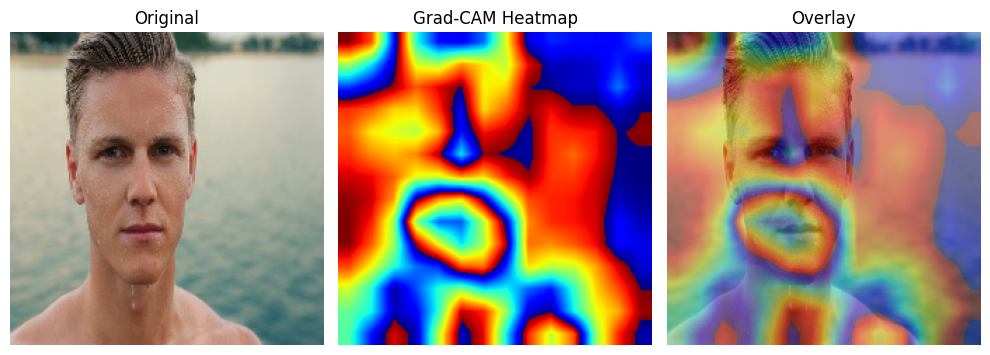


Generating Grad-CAM for EfficientNetB0 on image: image1-1.png


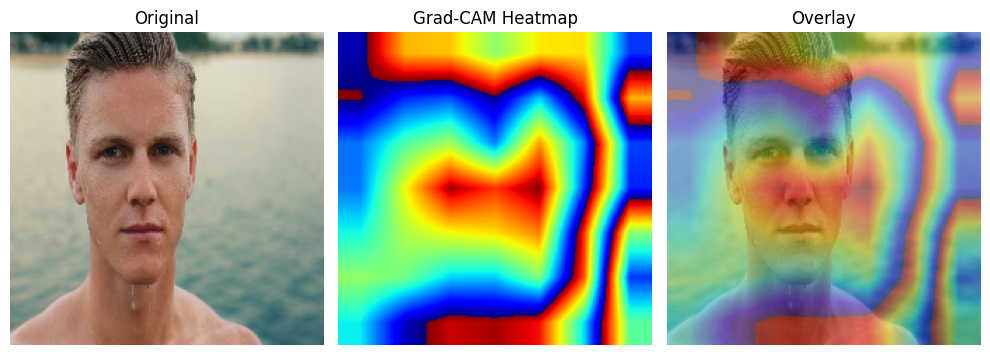


Generating Grad-CAM for VGG16 on image: Hand_0000032.jpg


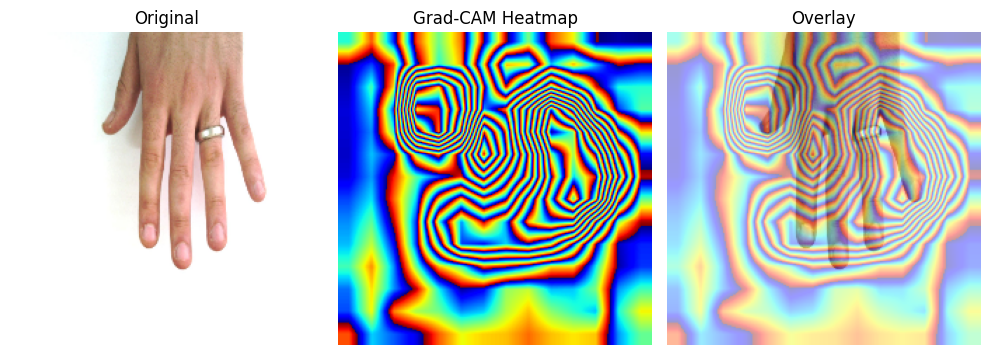


Generating Grad-CAM for EfficientNetB0 on image: Hand_0000032.jpg


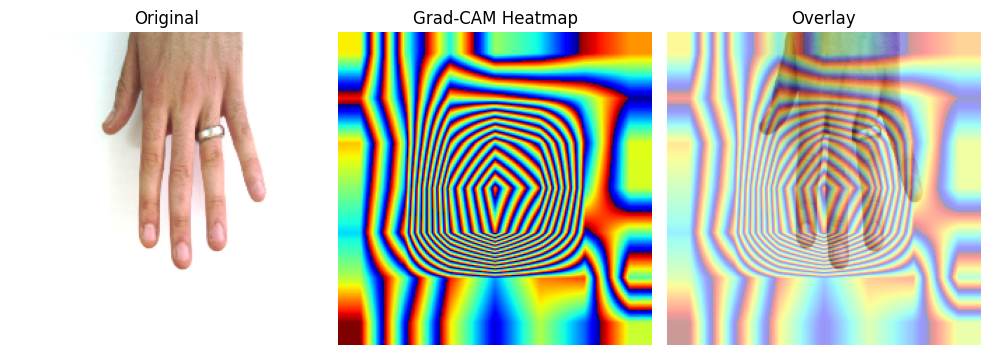


Generating Grad-CAM for VGG16 on image: Hand_0005164.jpg


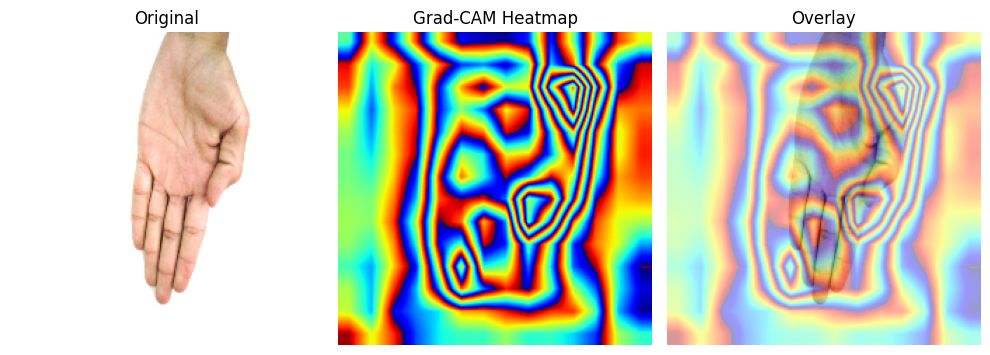


Generating Grad-CAM for EfficientNetB0 on image: Hand_0005164.jpg


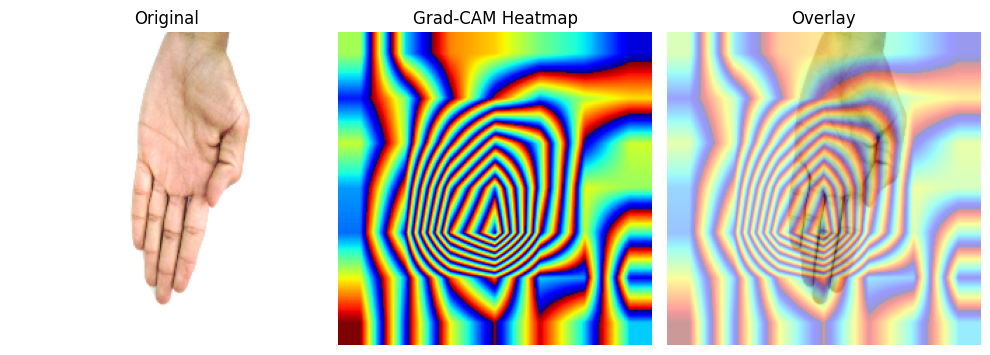


Generating Grad-CAM for VGG16 on image: Hand_0000507.jpg


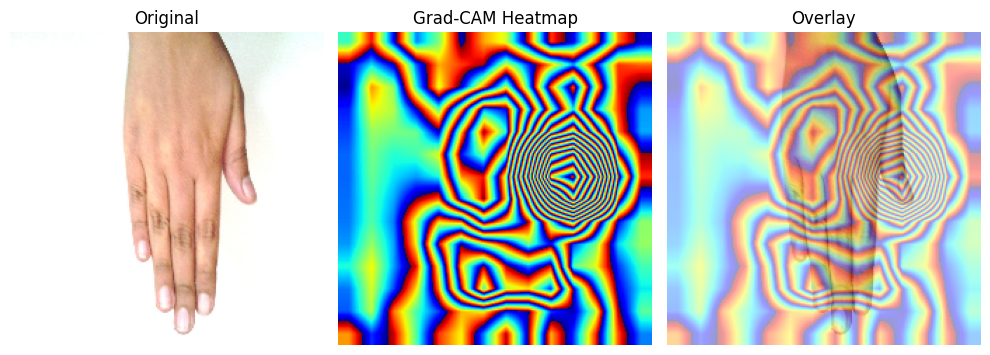


Generating Grad-CAM for EfficientNetB0 on image: Hand_0000507.jpg


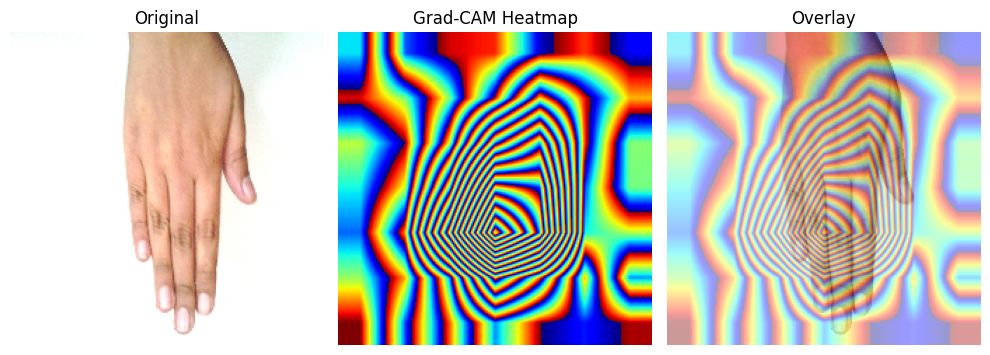

In [42]:
import cv2
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import os
import random

def get_img_array(img_path, size):
    img = cv2.imread(img_path)
    if img is None:
        print(f"Warning: Could not read image file: {img_path}")
        return None
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, size)
    img = img.astype(np.float32) / 255.0
    return np.expand_dims(img, axis=0)

def make_gradcam_heatmap(img_array, model, grad_model, last_conv_layer_name, pred_index=None):
    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_array)
        if pred_index is None:
            predictions_for_index = model.predict(img_array, verbose=0)
            # Binary classification (sigmoid output)
            if predictions_for_index.shape[-1] == 1:
                pred_index = 0
            else:
                pred_index = tf.argmax(predictions_for_index[0])

        class_channel = predictions[:, pred_index]

    grads = tape.gradient(class_channel, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_outputs = conv_outputs[0]
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)

    max_heatmap = tf.math.reduce_max(heatmap)
    if max_heatmap == 0:
        return np.zeros(heatmap.shape)
    heatmap = heatmap / max_heatmap
    return heatmap.numpy()

def display_gradcam(img_path, heatmap, alpha=0.4, size=(224,224)):
    img = cv2.imread(img_path)
    if img is None:
        print(f"Warning: Could not read image for display: {img_path}")
        return
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, size)

    heatmap_resized = cv2.resize(heatmap, (img.shape[1], img.shape[0]))
    heatmap_resized = np.uint8(255 * heatmap_resized)
    jet = plt.get_cmap("jet")
    jet_colors = jet(np.arange(256))[:, :3]
    jet_heatmap = jet_colors[heatmap_resized]
    jet_heatmap = np.uint8(jet_heatmap * 255)

    superimposed_img = cv2.addWeighted(img, 1 - alpha, jet_heatmap, alpha, 0)

    plt.figure(figsize=(10,4))
    plt.subplot(1,3,1)
    plt.imshow(img)
    plt.title('Original')
    plt.axis('off')
    plt.subplot(1,3,2)
    plt.imshow(heatmap_resized, cmap='jet')
    plt.title('Grad-CAM Heatmap')
    plt.axis('off')
    plt.subplot(1,3,3)
    plt.imshow(superimposed_img)
    plt.title('Overlay')
    plt.axis('off')
    plt.tight_layout()
    plt.show()

def get_last_conv_layer_name(model):
    for layer in reversed(model.layers):
        if isinstance(layer, tf.keras.layers.Conv2D):
            return layer.name
        if isinstance(layer, (tf.keras.Model, tf.keras.Sequential)):
            try:
                return get_last_conv_layer_name(layer)
            except ValueError:
                continue
    raise ValueError(f"No Conv2D layer found in model {model.name}.")

# === BEGIN MAIN GRAD-CAM PROCESS ===

# Build the basic CNN model if needed
try:
    basic_model.predict(tf.zeros((1, img_size[0], img_size[1], 3)))
except Exception as e:
    print(f"Could not build Basic CNN: {e}")

# Sample test images
test_gen.reset()
test_image_paths = test_gen.filepaths

num_sample_images = 4
if len(test_image_paths) > num_sample_images:
    sample_img_paths = random.sample(test_image_paths, num_sample_images)
elif len(test_image_paths) > 0:
    sample_img_paths = test_image_paths
else:
    print("No test images available to sample for Grad-CAM.")
    sample_img_paths = []

# Define models and last conv layers
try:
    basic_cnn_last_conv_layer = get_last_conv_layer_name(basic_model)
    models_to_explain = [
        (basic_model, basic_cnn_last_conv_layer, 'Basic CNN'),
        (vgg16_fixed_model, 'block5_conv3', 'VGG16'),
        (efficient_fixed_model, 'top_conv', 'EfficientNetB0')
    ]
except ValueError as e:
    print(f"Could not get last conv layer for Basic CNN: {e}. Skipping Basic CNN.")
    models_to_explain = [
        (vgg16_fixed_model, 'block5_conv3', 'VGG16'),
        (efficient_fixed_model, 'top_conv', 'EfficientNetB0')
    ]

# Build grad_model dict
grad_models = {}
for model, last_conv, model_name in models_to_explain:
    try:
        model.get_layer(last_conv)  # test if the layer exists
        grad_models[model_name] = tf.keras.models.Model(
            [model.inputs], [model.get_layer(last_conv).output, model.output]
        )
    except Exception as e:
        print(f"Could not build grad_model for {model_name}: {e}. Skipping Grad-CAM for this model.")
        grad_models[model_name] = None

# Generate Grad-CAM visualizations
if sample_img_paths:
    for img_path in sample_img_paths:
        img_array = get_img_array(img_path, img_size)
        if img_array is None:
            print(f"Skipping Grad-CAM for {os.path.basename(img_path)} due to image reading failure.")
            continue

        for model, last_conv, model_name in models_to_explain:
            if grad_models.get(model_name):
                print(f"\nGenerating Grad-CAM for {model_name} on image: {os.path.basename(img_path)}")
                try:
                    heatmap = make_gradcam_heatmap(img_array, model, grad_models[model_name], last_conv)
                    display_gradcam(img_path, heatmap, size=img_size)
                except Exception as e:
                    print(f"Error generating or displaying Grad-CAM for {model_name} on {os.path.basename(img_path)}: {e}")
else:
    print("No sample images available for Grad-CAM.")


Randomly selected image: /content/drive/MyDrive/archive (4)/Vitiligo DS/vitiligo/roi96.jpg


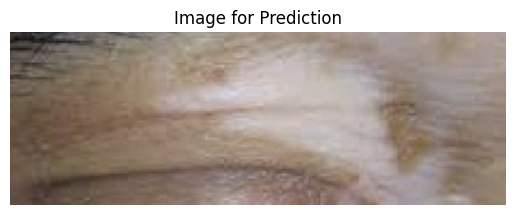

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step
Basic CNN Prediction: Vitiligo (score=0.9929)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
VGG16 Prediction: Vitiligo (score=0.9881)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step
EfficientNetB0 Prediction: Vitiligo (score=0.8003)


In [46]:
import random
import matplotlib.pyplot as plt
import cv2
import os
from glob import glob

# Get a list of all image paths in the data directory
all_image_paths = glob(os.path.join(data_dir, '*', '*'))

# Select a random image path
random_img_path = random.choice(all_image_paths)
print(f"Randomly selected image: {random_img_path}")

# Display the image
img_to_display = cv2.imread(random_img_path)
img_to_display = cv2.cvtColor(img_to_display, cv2.COLOR_BGR2RGB)
plt.imshow(img_to_display)
plt.title("Image for Prediction")
plt.axis('off')
plt.show()

# Preprocess the image
img_array = get_img_array(random_img_path, img_size)

# Define fixed class names for binary classification
class_names = ["Healthy", "Vitiligo"]

# Models to test
models_to_predict = [
    (basic_model, 'Basic CNN'),
    (vgg16_fixed_model, 'VGG16'),
    (efficient_fixed_model, 'EfficientNetB0')
]

for model, model_name in models_to_predict:
    prediction = model.predict(img_array)

    # For binary classification: threshold at 0.5
    predicted_class_index = 1 if prediction[0][0] >= 0.5 else 0
    predicted_class_name = class_names[predicted_class_index]

    print(f"{model_name} Prediction: {predicted_class_name} (score={prediction[0][0]:.4f})")